In [9]:
from monai.networks.nets import UNet
from monai.networks.layers import Norm
import torch

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet(
  spatial_dims=2,
  in_channels=1,
  out_channels=2,
  channels=(16, 32, 64, 128),
  strides=(2, 2, 2, 2),
  num_res_units=2,
).to(device)


In [11]:
from pathlib import Path
from monai.apps import DecathlonDataset
from monai.transforms import (
  Compose, LoadImaged, EnsureChannelFirstd, Orientationd, Spacingd,
  ScaleIntensityRanged, RandCropByPosNegLabeld, RandFlipd, ToTensord
)
from monai.data import DataLoader, list_data_collate
# your breath smells like the brownies :/ not in a good way :)

In [12]:
train_transforms = Compose([
  LoadImaged(keys=["image", "label"]),
  EnsureChannelFirstd(keys=["image", "label"]),
  Spacingd(keys=["image","label"], pixdim=(1.0,1.0,1.0)),
  Orientationd(keys=["image","label"], axcodes="RAS"),
  ScaleIntensityRanged(
    keys=["image"], 
    a_min=-100, a_max=400,
    b_min=0, 
    b_max=1, 
    clip=True
  ),
  RandCropByPosNegLabeld(
    keys=["image","label"], label_key="label",
    spatial_size=(96,96,96), pos=1, neg=1, num_samples=4
  ),
  ToTensord(keys=["image","label"])
])

root_dir = Path("./training_data/heart_segmentation_data")
root_dir.mkdir(parents=True, exist_ok=True)  # ensure local cache folder exists
task = "Task02_Heart"

train_ds = DecathlonDataset(
  root_dir=str(root_dir),
  task=task,
  section="training",   # or "validation"
  transform=train_transforms,
  download=True,        # this triggers automatic download
  cache_rate=0.0,       # start with 0 to avoid big RAM use
  num_workers=0,
)

train_loader = DataLoader(
  train_ds, batch_size=2, shuffle=True, num_workers=0,
  collate_fn=list_data_collate,
)


2025-11-29 22:47:58,271 - INFO - Verified 'Task02_Heart.tar', md5: 06ee59366e1e5124267b774dbd654057.
2025-11-29 22:47:58,272 - INFO - File exists: training_data/heart_segmentation_data/Task02_Heart.tar, skipped downloading.
2025-11-29 22:47:58,273 - INFO - Non-empty folder exists in training_data/heart_segmentation_data/Task02_Heart, skipped extracting.


<p> feed batches from ```train_loader ``` <b>directly into UNet</b> </p>

In [13]:
import matplotlib.pyplot as plt
import numpy as np

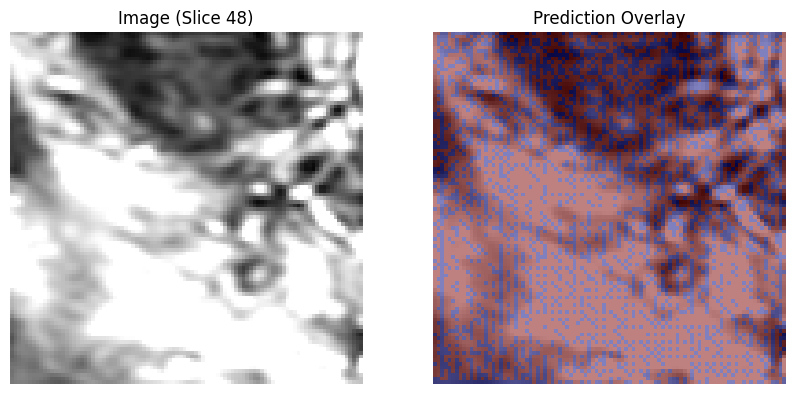

In [14]:
# Ensure the model is in eval mode for inference (disables dropout, fixes batchnorm)
model.eval() 

def flatten_depth_to_batch(volumes: torch.Tensor):
    b, c, d, h, w = volumes.shape
    flat = volumes.permute(0, 2, 1, 3, 4).reshape(b * d, c, h, w)
    return flat, b, d, h, w

with torch.no_grad(): # distinct context manager to save memory
    for i, batch in enumerate(train_loader):
        volumes = batch["image"].to(device)
        labels = batch["label"].to(device)

        flat_inputs, batch_size, depth, height, width = flatten_depth_to_batch(volumes)
        logits = model(flat_inputs)
        probs = torch.softmax(logits, dim=1)
        pred_mask_slices = torch.argmax(probs, dim=1)
        pred_mask = pred_mask_slices.view(batch_size, depth, height, width)

        image_np = volumes[:, 0].cpu().numpy()          # Shape: (B, D, H, W)
        pred_mask_np = pred_mask.cpu().numpy() # Shape: (B, D, H, W)

        b = 0 # Just grab the first item in the batch
        z = min(depth // 2, image_np.shape[1] - 1) # middle slice for visualization

        img_slice = image_np[b, z] 
        mask_slice = pred_mask_np[b, z] 

        plt.figure(figsize=(10, 5))

        plt.subplot(1, 2, 1)
        plt.imshow(img_slice, cmap="gray")
        plt.title(f"Image (Slice {z})")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(img_slice, cmap="gray")
        plt.imshow(mask_slice, cmap="jet", alpha=0.5) 
        plt.title("Prediction Overlay")
        plt.axis("off")

        plt.show()
        break


### save model

In [15]:
model.eval()
example = torch.randn(1, 1, 96, 96, device=device)
scripted_model = torch.jit.trace(model, example)
scripted_model.save("model.pt")


### Create config file for ML model

In [16]:
%%writefile config.pbtxt
name: "img_seg_model"
platform: "pytorch_libtorch"

input {
  name: "input"
  data_type: TYPE_FP32        # matches torch.float32 tensors
  dims: [ 1, 96, 96 ]         # (C, H, W)
  format: FORMAT_NCHW         # optional but recommended for images
}


output {
  name: "output"
  data_type: TYPE_FP32
  dims: [ 2, 96, 96 ] 
}


Overwriting config.pbtxt
